<a href="https://colab.research.google.com/github/loraleicook/MASC-520-Final-Project/blob/main/MASC_520_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MASC 520 Final Project: Using Deep Neural Networks to Predict Material Hardness**
### **Jingchen Wu, Loralei Cook, and Carolina Quinonez**
Project Github URL: https://github.com/loraleicook/MASC-520-Final-Project.git

In [ ]:
import os, re, time, shutil, zipfile, random, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torchvision import models
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore")


DATA_DIR, IMG_DIR = "data", "data/images"
LABELS_CSV = f"{DATA_DIR}/labels.csv"
TARGET_COL, MAG_COL, FILE_COL, SPLIT_COL = "hardness", "magnification", "filename", "split"
GROUP_COL = "sample_id"      # identifying images from the same sample
TAB_COLS  = []               # other numeric (grain size, porosity, etc.) features
COLUMN_MAP = {}              # renaming column headers
TEST_FILENAMES = []          # validating file matches
CROP_BOTTOM = 0              # cropping out information (SEM info banner)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU = DEVICE == "cuda"
BACKBONE = "resnet18"
PATCH    = 224 if GPU else 160
EPOCHS   = 20 if GPU else 10
REPS     = 4                 # random patches per image per epoch (set of training data)
FREEZE_EPOCHS, BATCH, SEED = 3, 16, 42
RUN_CV   = False             # CNN cross-validation

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("device:", DEVICE, "| patch:", PATCH, "| epochs:", EPOCHS)

device: cpu | patch: 160 | epochs: 10


#**Data Preparation**

In [ ]:
UPLOAD    = True
USE_DRIVE = False
DRIVE_CSV, DRIVE_ZIP = "/content/drive/MyDrive/sem/labels.csv", "/content/drive/MyDrive/sem/images.zip"
SCALE = 0.5
EXTS = (".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp")
t0 = time.time(); os.makedirs(IMG_DIR, exist_ok=True); zips = []
if USE_DRIVE:
    from google.colab import drive; drive.mount("/content/drive")
    shutil.copy(DRIVE_CSV, LABELS_CSV); zips = [DRIVE_ZIP]
elif UPLOAD:
    try:
        from google.colab import files
        for name, data in files.upload().items():
            low = name.lower()
            if low.endswith(".csv"):   open(LABELS_CSV, "wb").write(data)
            elif low.endswith(".zip"): open(f"{DATA_DIR}/{name}", "wb").write(data); zips.append(f"{DATA_DIR}/{name}")
            else:                      open(f"{IMG_DIR}/{name}", "wb").write(data)
    except ImportError:
        print("Not in Colab: put labels.csv and images in", DATA_DIR)
print(f"files ready ({time.time() - t0:.0f}s)")


lab = pd.read_csv(LABELS_CSV, encoding="utf-8-sig", sep=None, engine="python")
lab.columns = [str(c).strip() for c in lab.columns]
print("CSV columns:", list(lab.columns))
lab = lab.rename(columns=COLUMN_MAP)
for target, keys in [(FILE_COL, ["file", "image", "img", "name"]), (TARGET_COL, ["hard", "gpa", "hv"]),
                     (MAG_COL, ["mag", "zoom"]), (SPLIT_COL, ["split", "set", "train", "test"])]:
    if target not in lab.columns:
        hit = [c for c in lab.columns if c not in (FILE_COL, TARGET_COL, MAG_COL, SPLIT_COL)
               and any(k in c.lower() for k in keys)]
        if hit: lab = lab.rename(columns={hit[0]: target}); print(f"  using '{hit[0]}' as '{target}'")
for req in (FILE_COL, TARGET_COL):
    assert req in lab.columns, f"No '{req}' column found; set COLUMN_MAP. Columns: {list(lab.columns)}"


base = lambda v: os.path.basename(str(v).strip()).lower()
need = {base(v) for v in lab[FILE_COL]} | {os.path.splitext(base(v))[0] for v in lab[FILE_COL]}
for zp in zips:
    with zipfile.ZipFile(zp) as z:
        mem = [m for m in z.namelist() if m.lower().endswith(EXTS) and "__MACOSX" not in m]
        keep = [m for m in mem if base(m) in need or os.path.splitext(base(m))[0] in need]
        print(f"{os.path.basename(zp)}: {len(mem)} images in zip, extracting the {len(keep)} listed in the CSV")
        for m in keep:
            with z.open(m) as src, open(f"{IMG_DIR}/{os.path.basename(m)}", "wb") as dst: shutil.copyfileobj(src, dst)
    if zp.startswith(DATA_DIR): os.remove(zp)
print(f"extraction done ({time.time() - t0:.0f}s)")


idx = {}
for fn in os.listdir(IMG_DIR):
    if fn.lower().endswith(EXTS) and not fn.startswith("._"):
        idx[fn.lower()] = idx[os.path.splitext(fn)[0].lower()] = f"{IMG_DIR}/{fn}"
lab["path"] = [idx.get(base(v)) or idx.get(os.path.splitext(base(v))[0]) for v in lab[FILE_COL]]
bad = lab.loc[lab["path"].isna(), FILE_COL].tolist()
assert not bad, f"{len(bad)} CSV filenames have no image, e.g. {bad[:5]}; images seen: {list(idx)[:5]}"

# magnification
mag = pd.to_numeric(lab[MAG_COL].astype(str).str.extract(r"(\d+)")[0], errors="coerce") if MAG_COL in lab else np.nan
lab[MAG_COL] = pd.Series(mag, index=lab.index).fillna(pd.to_numeric(lab[FILE_COL].astype(str).str.extract(r"(\d+)\s*[xX]")[0], errors="coerce"))
assert lab[MAG_COL].notna().all(), "Couldn't determine magnification; add a 'magnification' column"

# train / test split
if SPLIT_COL in lab:
    lab[SPLIT_COL] = np.where(lab[SPLIT_COL].astype(str).str.lower().str.contains("test|hold|val"), "test", "train")
elif TEST_FILENAMES:
    lab[SPLIT_COL] = np.where(lab[FILE_COL].isin(TEST_FILENAMES), "test", "train")
else:
    print("WARNING: no split info -> holding out 8 random images as test. Set TEST_FILENAMES to use your real 8.")
    lab[SPLIT_COL] = "train"; lab.loc[np.random.RandomState(SEED).choice(lab.index, 8, replace=False), SPLIT_COL] = "test"
lab[TARGET_COL] = pd.to_numeric(lab[TARGET_COL], errors="coerce")
lab = lab.dropna(subset=[TARGET_COL]).reset_index(drop=True)

def load(p):
    im = cv2.imread(p, cv2.IMREAD_GRAYSCALE); assert im is not None, p
    if CROP_BOTTOM: im = im[:-CROP_BOTTOM]
    return cv2.resize(im, None, fx=SCALE, fy=SCALE, interpolation=cv2.INTER_AREA) if SCALE != 1 else im
with ThreadPoolExecutor(8) as ex: lab["img"] = list(ex.map(load, lab["path"]))
train_df = lab[lab[SPLIT_COL] == "train"].reset_index(drop=True)
test_df  = lab[lab[SPLIT_COL] == "test"].reset_index(drop=True)
y_train, y_test = train_df[TARGET_COL].values, test_df[TARGET_COL].values
print(f"train: {len(train_df)} | test: {len(test_df)} | magnifications: {lab[MAG_COL].value_counts().to_dict()}")
print(f"image size after scaling: {train_df['img'][0].shape} | data ready in {time.time() - t0:.0f}s")

MAGS = sorted(lab[MAG_COL].unique())
def tab(d):
    cols = [(d[MAG_COL] == m).astype(float).values for m in MAGS] + [d[c].astype(float).values for c in TAB_COLS]
    return np.stack(cols, 1).astype(np.float32)
metrics = lambda y, p: dict(MAE=mean_absolute_error(y, p), RMSE=mean_squared_error(y, p) ** 0.5, R2=r2_score(y, p))
groups = train_df[GROUP_COL].values if GROUP_COL and GROUP_COL in train_df else np.arange(len(train_df))
folds = list(GroupKFold(n_splits=min(5, len(set(groups)))).split(train_df, groups=groups))

Saving images.zip to images.zip
Saving labels.csv to labels.csv
files ready (1609s)
CSV columns: ['Filename', 'Hardness', 'Magnification', 'Split']
  using 'Filename' as 'filename'
  using 'Hardness' as 'hardness'
  using 'Magnification' as 'magnification'
  using 'Split' as 'split'
images.zip: 84 images in zip, extracting the 84 listed in the CSV
extraction done (1611s)
train: 76 | test: 8 | magnifications: {60: 55, 500: 21, 250: 4, 1000: 4}
image size after scaling: (1024, 1280) | data ready in 1625s


# **Random Forest and Ridge Regression**
For each image, features like brightness, texture, binary patterns, edge density, and sharpness are numerically computed. A ridge linear regression predicts hardness as a weighted sum o these features. These weights are chosen to fit the training data. A random forest of 200 decision trees, ending in predicted hardness, is trained on a random sample of data to evaluate the relationship of features. Both of these models are used as baselines before CNN analysis.

In [ ]:
def hc_features(img):
    g = cv2.resize(img, (256, 256), interpolation=cv2.INTER_AREA)
    glcm = graycomatrix((g // 8).astype(np.uint8), [1, 4], [0, np.pi / 2], levels=32, symmetric=True, normed=True)
    f = [g.mean(), g.std(), *np.percentile(g, [5, 95])]
    f += [graycoprops(glcm, p).mean() for p in ("contrast", "homogeneity", "energy", "correlation")]
    f += list(np.histogram(local_binary_pattern(g, 8, 1, "uniform"), bins=10, range=(0, 10), density=True)[0])
    f += [cv2.Canny(g, 50, 150).mean() / 255, cv2.Laplacian(g, cv2.CV_64F).var()]
    return np.array(f, np.float32)

t0 = time.time()
Xb_tr = np.hstack([np.stack(train_df["img"].map(hc_features)), tab(train_df)])
Xb_te = np.hstack([np.stack(test_df["img"].map(hc_features)),  tab(test_df)])
baselines = {"Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))),
             "RandomForest": RandomForestRegressor(200, min_samples_leaf=2, random_state=SEED, n_jobs=-1)}
base_pred = {}
for name, m in baselines.items():
    oof = np.zeros(len(train_df))
    for tr, va in folds:
        oof[va] = m.fit(Xb_tr[tr], y_train[tr]).predict(Xb_tr[va])
    base_pred[name] = m.fit(Xb_tr, y_train).predict(Xb_te)
    print(f"{name:12s} CV MAE={metrics(y_train, oof)['MAE']:.3f}  R2={metrics(y_train, oof)['R2']:.3f}")
print(f"baselines done in {time.time() - t0:.0f}s")

Ridge        CV MAE=2.490  R2=0.407
RandomForest CV MAE=2.389  R2=0.325
baselines done in 5s


## **CNN Regression**
For the CNN model, pretrained image networks (ResNet or EfficientNet) are shown small square "patches" cut from the SEM images. Each training patch is randomly flipped, rotated and brightness-adjusted so there is variety within the model. The network’s original classification layer is replaced with an identifier that combines what the network sees in the patch with numeric inputs like magnification and the predicted hardness. Training updates the new identifier for 3 epochs, then fine-tunes the whole network using gradually shrinking adjustments. At test time, the model predicts on a 3×3 grid of 9 patches per image, averages them, and converts the result back into real hardness units.

In [ ]:
MEAN, STD = np.float32([0.485, 0.456, 0.406]), np.float32([0.229, 0.224, 0.225])

def to_tensor(p):
    x = (np.repeat(p[..., None], 3, 2).astype(np.float32) / 255 - MEAN) / STD
    return torch.from_numpy(x.transpose(2, 0, 1).copy())

def fit_size(img):
    h, w = img.shape
    return img if min(h, w) >= PATCH else cv2.resize(img, (max(w, PATCH), max(h, PATCH)))

def rand_patch(img):
    img = fit_size(img); h, w = img.shape
    y, x = np.random.randint(0, h - PATCH + 1), np.random.randint(0, w - PATCH + 1)
    p = img[y:y + PATCH, x:x + PATCH]
    if np.random.rand() < .5: p = p[:, ::-1]
    if np.random.rand() < .5: p = p[::-1]
    p = np.rot90(p, np.random.randint(4)).astype(np.float32)
    return np.clip(p * np.random.uniform(.85, 1.15) + np.random.uniform(-15, 15), 0, 255).astype(np.uint8)

def grid_patches(img):
    img = fit_size(img); h, w = img.shape
    return [img[y:y + PATCH, x:x + PATCH] for y in np.linspace(0, h - PATCH, 3).astype(int)
                                          for x in np.linspace(0, w - PATCH, 3).astype(int)]

class HardnessNet(nn.Module):
    def __init__(self, n_tab):
        super().__init__()
        if BACKBONE.startswith("resnet"):
            W = {"resnet18": models.ResNet18_Weights, "resnet50": models.ResNet50_Weights}[BACKBONE].DEFAULT
            self.body = getattr(models, BACKBONE)(weights=W); n = self.body.fc.in_features; self.body.fc = nn.Identity()
        else:
            self.body = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
            n = self.body.classifier[1].in_features; self.body.classifier = nn.Identity()
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(n + n_tab, 1))
    def forward(self, x, t):
        return self.head(torch.cat([self.body(x), t], 1)).squeeze(1)

def fit_cnn(d, epochs=EPOCHS):
    mu, sd = d[TARGET_COL].mean(), d[TARGET_COL].std()
    sc = StandardScaler().fit(tab(d))
    T = sc.transform(tab(d)).astype(np.float32); Y = ((d[TARGET_COL].values - mu) / sd).astype(np.float32)
    imgs = list(d["img"])
    model = HardnessNet(T.shape[1]).to(DEVICE)
    opt = torch.optim.AdamW([{"params": model.head.parameters(), "lr": 1e-3},
                             {"params": model.body.parameters(), "lr": 1e-4}], weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    loss_fn, history, t0 = nn.SmoothL1Loss(), [], time.time()
    for ep in range(epochs):
        for p in model.body.parameters(): p.requires_grad = ep >= FREEZE_EPOCHS
        model.train(); order = np.concatenate([np.random.permutation(len(imgs)) for _ in range(REPS)]); tot = 0
        for b in np.array_split(order, max(1, len(order) // BATCH)):
            x = torch.stack([to_tensor(rand_patch(imgs[i])) for i in b]).to(DEVICE)
            loss = loss_fn(model(x, torch.from_numpy(T[b]).to(DEVICE)), torch.from_numpy(Y[b]).to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        sched.step(); history.append(tot / len(order))
        if ep % 5 == 0 or ep == epochs - 1:
            print(f"epoch {ep + 1:2d}/{epochs} loss={history[-1]:.4f} ({time.time() - t0:.0f}s)")
    return model, mu, sd, sc, history

@torch.no_grad()
def predict_cnn(bundle, d):
    model, mu, sd, sc = bundle[:4]; model.eval()
    T = sc.transform(tab(d)).astype(np.float32); out = []
    for img, t in zip(d["img"], T):
        x = torch.stack([to_tensor(p) for p in grid_patches(img)]).to(DEVICE)
        out.append(model(x, torch.from_numpy(t).repeat(len(x), 1).to(DEVICE)).mean().item())
    return np.array(out) * sd + mu

In [ ]:
# Cross-validation (CV) of the CNN
if RUN_CV:
    oof = np.zeros(len(train_df))
    for tr, va in folds:
        b = fit_cnn(train_df.iloc[tr].reset_index(drop=True))
        oof[va] = predict_cnn(b, train_df.iloc[va].reset_index(drop=True))
    print("CNN CV:", {k: round(v, 3) for k, v in metrics(y_train, oof).items()})

## **Training and Results**

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 114MB/s]


epoch  1/10 loss=0.5093 (18s)
epoch  6/10 loss=0.3408 (236s)
epoch 10/10 loss=0.2849 (422s)


,MAE,RMSE,R2
Ridge,14.389,20.802,-0.729
RandomForest,14.017,21.313,-0.815
CNN (resnet18),13.672,20.445,-0.670


,filename,magnification,hardness,Ridge,RandomForest,CNN (resnet18)
0,esd_pla_250x.jpg,250,69.54,78.392,76.808,77.615
1,esd_abs_250x.jpg,250,70.02,73.529,75.686,76.412
2,esd_tpu_250x.jpg,250,35.26,73.884,75.739,75.081
3,esd_onyx_250x.jpg,250,74.86,73.805,73.137,75.192
4,esd_pla_1000x.jpg,1000,69.54,81.481,76.652,78.218
5,esd_abs_1000x.jpg,1000,70.02,79.760,77.168,76.612
6,esd_tpu_1000x.jpg,1000,35.26,75.756,77.753,74.415
7,esd_onyx_1000x.jpg,1000,74.86,73.962,75.109,74.531


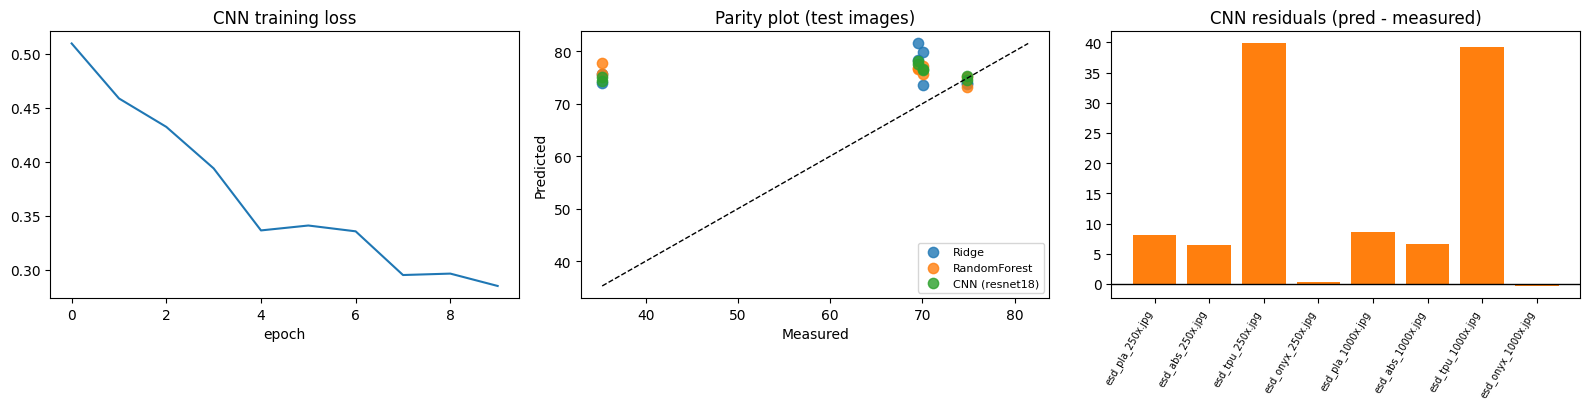

In [ ]:
bundle = fit_cnn(train_df)
cnn_pred = predict_cnn(bundle, test_df)

preds = {**base_pred, f"CNN ({BACKBONE})": cnn_pred}
display(pd.DataFrame({k: metrics(y_test, p) for k, p in preds.items()}).T.round(3))
out = test_df[[FILE_COL, MAG_COL, TARGET_COL]].copy()
for k, p in preds.items(): out[k] = p
display(out.round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].plot(bundle[4]); ax[0].set(title="CNN training loss", xlabel="epoch")
lo, hi = min(y_test.min(), *(p.min() for p in preds.values())), max(y_test.max(), *(p.max() for p in preds.values()))
ax[1].plot([lo, hi], [lo, hi], "k--", lw=1)
for k, p in preds.items(): ax[1].scatter(y_test, p, s=55, alpha=.8, label=k)
ax[1].set(title="Parity plot (test images)", xlabel="Measured", ylabel="Predicted"); ax[1].legend(fontsize=8)
ax[2].bar(range(len(y_test)), cnn_pred - y_test, color=np.where(test_df[MAG_COL] == MAGS[0], "C0", "C1"))
ax[2].axhline(0, color="k", lw=1); ax[2].set(title="CNN residuals (pred - measured)")
ax[2].set_xticks(range(len(y_test))); ax[2].set_xticklabels(test_df[FILE_COL], rotation=60, ha="right", fontsize=7)
plt.tight_layout(); plt.show()

torch.save({"state_dict": bundle[0].state_dict(), "backbone": BACKBONE, "mu": float(bundle[1]), "sd": float(bundle[2])}, "hardness_cnn.pt")